# Exploratory analysis: FOODS demand in store CA_1

Goal: understand demand before modelling. Each finding ends with the modelling decision it leads to, and is copied to `FINDINGS.md` only after it has been verified.

All numbers are computed by SQL against the dbt marts (`marts.fct_daily_sales` and its dimensions), so the notebook can be rerun top to bottom.

> Note: The database is opened **read-only**. Restart the kernel before running `dbt build`, otherwise dbt cannot write to the file.

In [21]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
import yaml
from scipy import stats

# Find the project root (the folder containing config.yaml), so the notebook
# works whether it is started from the repo root or from analysis/.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.yaml").exists())
config = yaml.safe_load((ROOT / "config.yaml").read_text())

con = duckdb.connect(str(ROOT / config["paths"]["database"]), read_only=True)
con.execute("SET enable_progress_bar = false")


def q(sql: str) -> pd.DataFrame:
    """Run a SQL query against the database and return a DataFrame."""
    return con.sql(sql).df()


plt.rcParams.update({"figure.figsize": (12, 4), "axes.spines.top": False,
                     "axes.spines.right": False})

print(f"Scope: store {config['scope']['store_id']}, category {config['scope']['cat_id']}")
q("SELECT COUNT(*) AS n_rows, COUNT(DISTINCT item_id) AS n_items, "
  "MIN(date) AS first_date, MAX(date) AS last_date FROM marts.fct_daily_sales")

Scope: store CA_1, category FOODS


,n_rows,n_items,first_date,last_date
0,2260241,1437,2011-01-29,2016-05-22


## 1. Overall pattern: trend, yearly seasonality, Christmas

### 1a. Daily totals
One row per day: total units sold, and how many items were active (launched) that day.

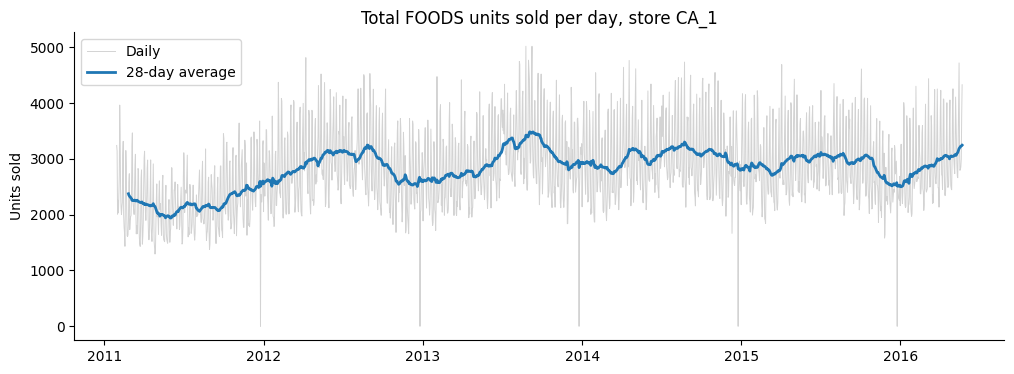

,date,total_units,n_active_items,total_units_28d
0,2011-01-29,3239.0,628,NaN
1,2011-01-30,3137.0,628,NaN
2,2011-01-31,2008.0,628,NaN
3,2011-02-01,2258.0,628,NaN
4,2011-02-02,2032.0,628,NaN


In [22]:
# 1a. One row per day: total units sold and number of active (launched) items.
# The fact table has one row per item per day from launch onwards, so
# COUNT(*) per day = number of items that existed in the store that day.
# ROWS-based windows are only correct because every date has a row
# (guaranteed by tests/assert_no_missing_dates_after_launch.sql).

daily = q("""
    SELECT
        date,
        SUM(units_sold)  AS total_units,
        COUNT(*)         AS n_active_items,
        -- Only return a 28-day average when the window really has 28 days.
        -- For the first 27 days the window is partial, which would create a
        -- misleading spike, so those days get NULL instead.
        CASE WHEN COUNT(*) OVER w = 28
             THEN AVG(SUM(units_sold)) OVER w
        END              AS total_units_28d
    FROM marts.fct_daily_sales
    GROUP BY date
    WINDOW w AS (ORDER BY date ROWS BETWEEN 27 PRECEDING AND CURRENT ROW)
    ORDER BY date
""")

fig, ax = plt.subplots()
ax.plot(daily["date"], daily["total_units"], color="lightgray", linewidth=0.7, label="Daily")
ax.plot(daily["date"], daily["total_units_28d"], color="tab:blue", linewidth=2, label="28-day average")
ax.set_title("Total FOODS units sold per day, store CA_1")
ax.set_ylabel("Units sold")
ax.legend()
plt.show()

daily.head()

### 1b. Seasonality, checked with numbers
Average daily units for each calendar month and year, so the seasonality seen in the chart is verified rather than judged by eye.

In [23]:
# Average daily units per calendar month, per year, to verify seasonality.
monthly = q("""
    SELECT year(date) AS year, month(date) AS month,
           AVG(total) AS avg_daily_units
    FROM (SELECT date, SUM(units_sold) AS total
          FROM marts.fct_daily_sales GROUP BY date)
    GROUP BY ALL
    ORDER BY year, month
""")
monthly.pivot(index="month", columns="year", values="avg_daily_units").round(0)

year,2011,2012,2013,2014,2015,2016
month,,,,,,
1,2795.0,2551.0,2560.0,2838.0,2886.0,2741.0
2,2326.0,2734.0,2724.0,2827.0,2819.0,2858.0
3,2171.0,2862.0,2784.0,2912.0,2812.0,2928.0
4,2120.0,3012.0,2664.0,3128.0,2991.0,3074.0
5,1970.0,3070.0,2857.0,2973.0,3069.0,3342.0
6,2094.0,3165.0,3167.0,3084.0,3038.0,NaN
7,2189.0,3006.0,3242.0,3166.0,3005.0,NaN
8,2125.0,3173.0,3440.0,3277.0,3044.0,NaN
9,2136.0,3018.0,3390.0,3064.0,2941.0,NaN


In [24]:
# Seasonality without the mix effect: units per item for the 628 original
# items only, so the group doesn't change during the year.
# 25 December is excluded (store closed, see 1d).
cohort_monthly = q("""
    SELECT year(f.date) AS year, month(f.date) AS month,
           AVG(f.units_sold) AS units_per_item
    FROM marts.fct_daily_sales AS f
    JOIN marts.dim_item AS i ON f.item_id = i.item_id
    WHERE i.launch_date = DATE '2011-01-29'
      AND NOT (month(f.date) = 12 AND day(f.date) = 25)
    GROUP BY ALL
    ORDER BY year, month
""")
cohort_table = cohort_monthly.pivot(index="month", columns="year", values="units_per_item")

# First attempt at a seasonal index: each month relative to its calendar
# year's average, averaged over the full years 2012-2015 (1.10 = 10% above).
# Biased by the downward trend (see 1c), so it is corrected in the next cell.
full_years = cohort_table[[2012, 2013, 2014, 2015]]
seasonal_index = (full_years / full_years.mean()).mean(axis=1).round(2)

display(cohort_table.round(2))
seasonal_index

year,2011,2012,2013,2014,2015,2016
month,,,,,,
1,4.45,3.28,2.77,2.45,2.52,2.27
2,3.51,3.38,2.77,2.47,2.47,2.47
3,3.07,3.30,2.89,2.53,2.49,2.55
4,2.96,3.38,2.77,2.83,2.51,2.62
5,2.76,3.39,3.00,2.75,2.58,2.79
6,2.89,3.56,3.26,2.89,2.67,NaN
7,3.01,3.39,3.36,2.92,2.71,NaN
8,2.87,3.67,3.57,2.95,2.69,NaN
9,2.80,3.42,3.48,2.81,2.64,NaN


month
1     0.95
2     0.95
3     0.97
4     0.99
5     1.01
6     1.07
7     1.07
8     1.11
9     1.06
10    0.98
11    0.92
12    0.90
dtype: float64

**Removing the trend.** Units per item fall by about 8% a year (see 1c). Dividing by the *calendar-year* average therefore makes late months look low simply because they come later in a declining year. Classical decomposition divides each month by a **centred 12-month moving average** instead, which follows the trend, so only the seasonal effect is left.

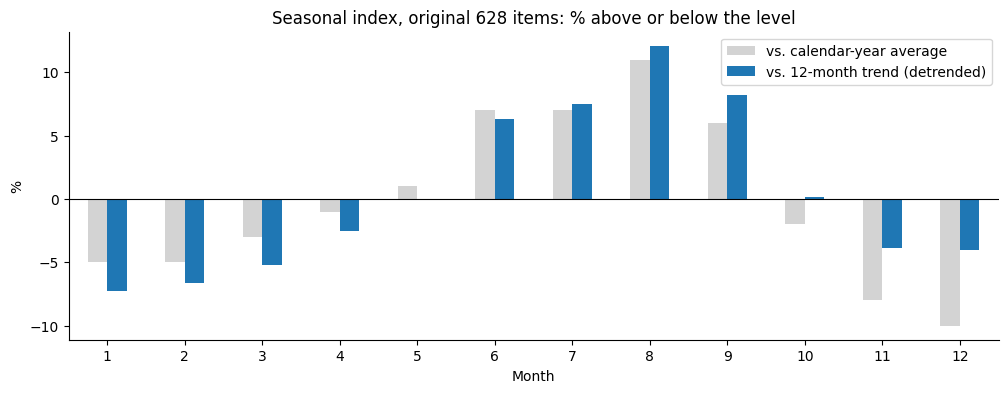

year,2012,2013,2014,2015
month,,,,
1,1.01,0.90,0.85,0.95
2,1.02,0.90,0.87,0.94
3,0.98,0.94,0.91,0.95
4,1.00,0.90,1.03,0.96
5,1.01,0.98,1.00,1.00
6,1.07,1.08,1.06,1.05
7,1.03,1.12,1.07,1.07
8,1.13,1.20,1.08,1.07
9,1.07,1.18,1.03,1.05


Lowest month per year: {2012: 11, 2013: 2, 2014: 1, 2015: 2}
Highest month per year: {2012: 8, 2013: 8, 2014: 8, 2015: 7}


,vs. calendar-year average,vs. 12-month trend (detrended)
month,,
1,0.95,0.93
2,0.95,0.93
3,0.97,0.95
4,0.99,0.97
5,1.01,1.00
6,1.07,1.06
7,1.07,1.07
8,1.11,1.12
9,1.06,1.08


In [25]:
# Seasonal index without the trend: each month divided by a centred 12-month
# moving average. 12 is even, so a 12-month average falls between two months;
# averaging two neighbouring 12-month averages re-centres it ("2x12 MA").
# Only complete months are used: February 2011 to April 2016.
cohort_ts = q("""
    SELECT
        date_trunc('month', f.date) AS month_start,
        AVG(f.units_sold)           AS units_per_item
    FROM marts.fct_daily_sales AS f
    JOIN marts.dim_item AS i ON f.item_id = i.item_id
    WHERE i.launch_date = DATE '2011-01-29'
      AND NOT (month(f.date) = 12 AND day(f.date) = 25)
      AND f.date >= DATE '2011-02-01' AND f.date < DATE '2016-05-01'
    GROUP BY ALL
    ORDER BY month_start
""")
cohort_ts["trend"] = (cohort_ts["units_per_item"].rolling(12, center=True).mean()
                      .rolling(2).mean().shift(-1))
cohort_ts["ratio"] = cohort_ts["units_per_item"] / cohort_ts["trend"]
cohort_ts["year"] = cohort_ts["month_start"].dt.year
cohort_ts["month"] = cohort_ts["month_start"].dt.month

# Same full years as the first index (2012-2015), so the two are comparable.
ratio_table = (cohort_ts.pivot(index="month", columns="year", values="ratio")
               [[2012, 2013, 2014, 2015]])
seasonal_index_detrended = ratio_table.mean(axis=1)

comparison = pd.DataFrame({
    "vs. calendar-year average": seasonal_index,
    "vs. 12-month trend (detrended)": seasonal_index_detrended,
})

ax = (comparison - 1).mul(100).plot.bar(color=["lightgray", "tab:blue"], rot=0)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Seasonal index, original 628 items: % above or below the level")
ax.set_xlabel("Month")
ax.set_ylabel("%")
plt.show()

display(ratio_table.round(2))
print("Lowest month per year:", ratio_table.idxmin().to_dict())
print("Highest month per year:", ratio_table.idxmax().to_dict())
comparison.round(2)

### 1b. What the chart shows

- **Trend:** Total sales rose from about 2,000–2,200 units/day in mid-2011 to about 3,000 by mid-2012. After that there is no clear trend: the 28-day average moves between roughly 2,500 and 3,400 from 2012 to 2016. (Section 1c shows this growth comes from more items, not more demand per item.)
- **Yearly seasonality:** The monthly table of *total* sales is affected by the mix effect (the store added items every year until 2015), so seasonality is measured on the fixed group of 628 original items. Because their sales also decline by about 8% a year (1c), each month is compared with a centred 12-month moving average rather than its calendar-year average (detrended seasonal index, 2012–2015):
  - **Summer peak: June–September are 6–12% above the level**, highest in August (+12%). The peak month was July or August in every full year.
  - **Winter low: January–March are 5–7% below the level.** The lowest month was January or February in three of the four years (2012: November).
  - **October–December are close to normal** (0 to −4%). The first, calendar-year index put November–December 8–10% below average, but most of that was the downward trend reaching the end of each year, not a seasonal effect.
  - Peak to trough (August vs. January/February): about **20%**. The summer peak is consistent across years; the winter low varies more from year to year.
  - 2011 is not used: January 2011 contains only 3 days, and the first year the cohort was still settling.
- **Christmas:** One sharp drop to zero every year, on 25 December (confirmed in 1d).
- **Anything else:** The daily line has a strong, regular up-and-down pattern within each week (analysed in section 2).

**Modelling decision:** add **month** (or day-of-year) as a feature. The seasonality is real: it appears in a fixed group of items after removing the trend, so it is caused neither by new products being added nor by the decline in demand.

### 1c. Is the trend real?
If total sales rise, is it because customers buy more of each item, or because the store stocks more items? The first chart below splits total sales into the number of items and units per item; the second removes the effect of new items by following a fixed group of items.

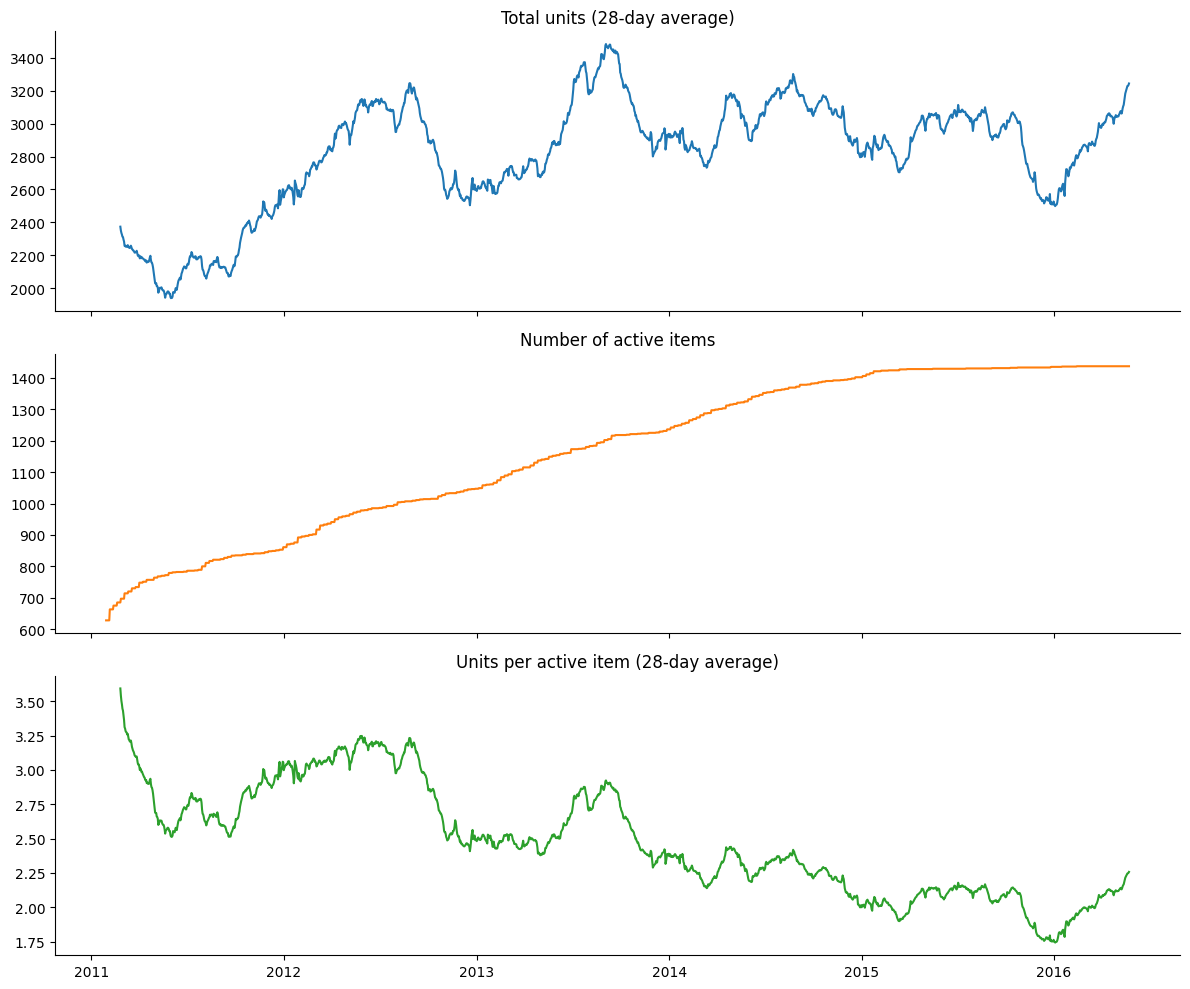

In [26]:
# 1c. Split total sales into (number of active items) x (units per item).

daily["units_per_item"] = daily["total_units"] / daily["n_active_items"]
daily["units_per_item_28d"] = daily["units_per_item"].rolling(28).mean()

fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

axes[0].plot(daily["date"], daily["total_units_28d"], color="tab:blue")
axes[0].set_title("Total units (28-day average)")

axes[1].plot(daily["date"], daily["n_active_items"], color="tab:orange")
axes[1].set_title("Number of active items")

axes[2].plot(daily["date"], daily["units_per_item_28d"], color="tab:green")
axes[2].set_title("Units per active item (28-day average)")

plt.tight_layout()
plt.show()

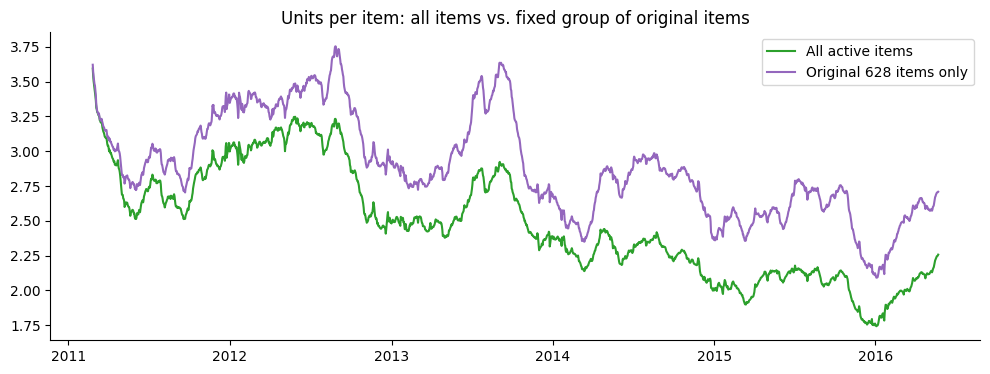

In [27]:
# True demand trend: follow only the items present from day one,
# so the group doesn't change over time (removes the mix effect).
cohort = q("""
    SELECT f.date, AVG(f.units_sold) AS units_per_item
    FROM marts.fct_daily_sales AS f
    JOIN marts.dim_item AS i ON f.item_id = i.item_id
    WHERE i.launch_date = DATE '2011-01-29'
    GROUP BY f.date
    ORDER BY f.date
""")
cohort["units_per_item_28d"] = cohort["units_per_item"].rolling(28).mean()

fig, ax = plt.subplots()
ax.plot(daily["date"], daily["units_per_item_28d"], label="All active items", color="tab:green")
ax.plot(cohort["date"], cohort["units_per_item_28d"], label="Original 628 items only", color="tab:purple")
ax.set_title("Units per item: all items vs. fixed group of original items")
ax.legend()
plt.show()

In [28]:
# Numbers quoted in the 1c conclusion: yearly units per item for the 628
# original items vs all items (25 December excluded, store closed), and
# whether any original item stopped selling.
yearly = q("""
    SELECT
        year(f.date) AS year,
        AVG(f.units_sold) FILTER (WHERE i.launch_date = DATE '2011-01-29') AS original_items,
        AVG(f.units_sold)                                                 AS all_items
    FROM marts.fct_daily_sales AS f
    JOIN marts.dim_item AS i ON f.item_id = i.item_id
    WHERE NOT (month(f.date) = 12 AND day(f.date) = 25)
    GROUP BY ALL
    ORDER BY year
""")
display(yearly.round(2))

q("""
    -- Original items with no sale in the last 180 days of the data
    SELECT
        COUNT(*) AS original_items,
        COUNT(*) FILTER (
            WHERE last_sale_date < (SELECT MAX(date) FROM marts.fct_daily_sales) - 179
        ) AS no_sale_last_180_days
    FROM (
        SELECT f.item_id, MAX(f.date) FILTER (WHERE f.units_sold > 0) AS last_sale_date
        FROM marts.fct_daily_sales AS f
        JOIN marts.dim_item AS i ON f.item_id = i.item_id
        WHERE i.launch_date = DATE '2011-01-29'
        GROUP BY f.item_id
    )
""")

,year,original_items,all_items
0,2011,3.08,2.86
1,2012,3.31,2.95
2,2013,3.02,2.57
3,2014,2.72,2.26
4,2015,2.53,2.03
5,2016,2.53,2.07


,original_items,no_sale_last_180_days
0,628,0


### 1c. Conclusion: total growth comes from a wider range, while demand per product fell

- **Active items** more than doubled, from 628 at the start of 2011 to 1,437 by 2016. Most items were added between 2011 and early 2015, after which the range is almost stable.
- **Units per active item** *fell*, from about 3.0–3.2 in 2012 to about 2.0–2.2 in 2015–2016.
- So the rise in total sales comes from the store **stocking more products**, not from customers buying more of each one.

**But "units per active item" is not pure "demand per product".** The items added later are probably slower sellers: niche products added to an already broad range, and new items that need time to build demand. Adding many slow items pulls the *average* down even if demand for each original product stayed the same. This is a **composition (mix) effect**: the average changes because the group changes, not because the items change.

**Fixed-group check (original 628 items, numbers from the cell above):** The purple line also falls, so the decline is **not only a mix effect**. Units per item for the original items fell from 3.31 per day (2012) to 2.53 (2015), **−24%**, while the average over all items fell from 2.95 to 2.03, **−31%**. The purple line is always above the green one, and the gap widens over time, which confirms that newer items sell less than established ones. None of the original items stopped selling (all had sales in the last 180 days), so the decline is not caused by discontinued products. A likely explanation is **cannibalisation**: as the range more than doubled, customers spread their purchases over more products, so each existing item sold less. (This is a hypothesis; the data doesn't show why customers switched.)

**In short:** total sales grew because the store stocked more products, while demand per individual product fell, both for old items and on average.

**Modelling decisions:**
- New items behave differently from established ones, so the model needs a **days since launch** feature, and errors should be checked by sales speed (fast/slow movers), not only in total.
- Demand per item drifts down over time (about −8% a year for established items), so 2012 data shows a higher level than today. The model needs features that track each item's **recent level** (lags and rolling means) rather than a fixed level learned from all history, and validation must use the most recent periods (rolling-origin CV), where this drift is visible.

### 1d. Verify Christmas with a query
Every day with zero total sales, found by query rather than by eye.

In [29]:
# 1d. Every day with zero total sales.
zero_days = q("""
    SELECT
        date,
        dayname(date)       AS weekday,
        SUM(units_sold)     AS total_units,
        COUNT(*)            AS n_active_items
    FROM marts.fct_daily_sales
    GROUP BY date
    HAVING SUM(units_sold) = 0
    ORDER BY date
""")
zero_days

,date,weekday,total_units,n_active_items
0,2011-12-25,Sunday,0.0,853
1,2012-12-25,Tuesday,0.0,1046
2,2013-12-25,Wednesday,0.0,1231
3,2014-12-25,Thursday,0.0,1402
4,2015-12-25,Friday,0.0,1433


### 1d. Answer

- **Only 25 December, and every year in the data (2011–2015).** No other day has zero total sales. 2016 has no Christmas because the data ends in May 2016.
- On each Christmas, **every active item has a row with 0 units** (853 items in 2011, rising to 1,433 in 2015). So the data is not missing: the **store was closed**.

**What this means for Stage 3:**
These zeros are not zero demand. If nothing tells the model the store was closed, it would learn that ~1,400 products all had zero demand on one day each year, and the zeros would also distort the features: the rolling averages and lag features around late December and January (e.g. lag_28 in late January) would include a fake zero day.

**Modelling decision:** add an `is_store_closed` flag (TRUE on 25 December), exclude closed days from training and evaluation, and exclude them when computing lag and rolling features. When forecasting a future 25 December, predict 0 directly from the flag.

## 2. Weekly pattern: how strong is the weekend effect?

**Method.** Each day is compared with the average of its own Walmart week (Saturday to Friday). This removes the trend, the yearly season and the mix effect from section 1, leaving only the weekday pattern. Units per active item are used, and 25 December is excluded (store closed).

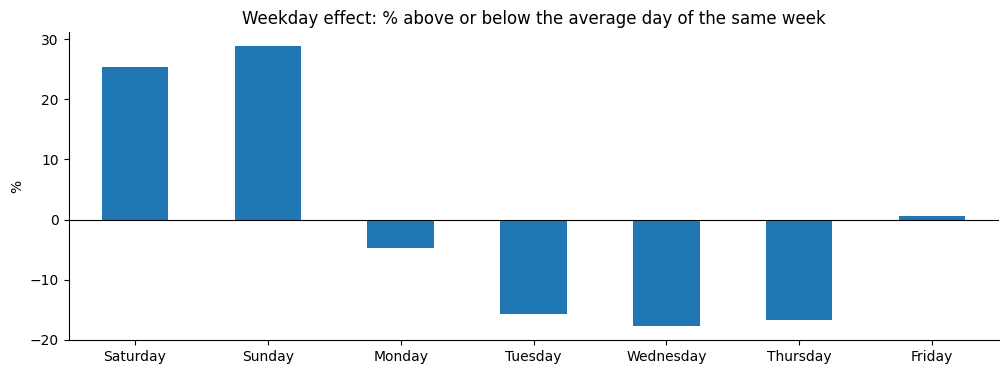

Complete weeks: 272
Friedman test: chi2 = 1266, p = 2.4e-270
Weekend (Sat+Sun) vs midweek (Tue-Thu): 1.53x
Share of weeks where the best day is Saturday or Sunday: 96%


weekday
Saturday     1.254
Sunday       1.288
Monday       0.953
Tuesday      0.843
Wednesday    0.823
Thursday     0.834
Friday       1.006
Name: vs_week, dtype: float64

In [30]:
# Daily units per active item with calendar attributes (used in sections 2 and 3).
day = q("""
    SELECT
        f.date,
        AVG(f.units_sold)       AS units_per_item,
        ANY_VALUE(d.wm_yr_wk)   AS wm_yr_wk,
        ANY_VALUE(d.weekday)    AS weekday,
        ANY_VALUE(d.is_snap)    AS is_snap,
        ANY_VALUE(d.is_event)   AS is_event,
        ANY_VALUE(d.event_type) AS event_type
    FROM marts.fct_daily_sales AS f
    JOIN marts.dim_date AS d ON f.date = d.date
    WHERE NOT (month(f.date) = 12 AND day(f.date) = 25)
    GROUP BY f.date
    ORDER BY f.date
""")
day["date"] = pd.to_datetime(day["date"])

WEEKDAYS = ["Saturday", "Sunday", "Monday", "Tuesday", "Wednesday", "Thursday", "Friday"]

# Only complete weeks (weeks containing 25 December have 6 days).
full_weeks = day[day.groupby("wm_yr_wk")["date"].transform("count") == 7].copy()
full_weeks["vs_week"] = (full_weeks["units_per_item"]
                         / full_weeks.groupby("wm_yr_wk")["units_per_item"].transform("mean"))
weekday_index = full_weeks.groupby("weekday")["vs_week"].mean().reindex(WEEKDAYS)

ax = (weekday_index - 1).mul(100).plot.bar(color="tab:blue", rot=0)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Weekday effect: % above or below the average day of the same week")
ax.set_ylabel("%")
ax.set_xlabel("")
plt.show()

# Significance: Friedman test, a non-parametric test for repeated measures.
# Each week is a block, so the weekdays are always compared within the same week.
by_week = full_weeks.pivot(index="wm_yr_wk", columns="weekday", values="units_per_item")[WEEKDAYS]
friedman = stats.friedmanchisquare(*[by_week[d] for d in WEEKDAYS])
weekend_vs_midweek = (weekday_index[["Saturday", "Sunday"]].mean()
                      / weekday_index[["Tuesday", "Wednesday", "Thursday"]].mean())
top_day_is_weekend = by_week.idxmax(axis=1).isin(["Saturday", "Sunday"]).mean()

print(f"Complete weeks: {len(by_week)}")
print(f"Friedman test: chi2 = {friedman.statistic:.0f}, p = {friedman.pvalue:.1e}")
print(f"Weekend (Sat+Sun) vs midweek (Tue-Thu): {weekend_vs_midweek:.2f}x")
print(f"Share of weeks where the best day is Saturday or Sunday: {top_day_is_weekend:.0%}")
weekday_index.round(3)

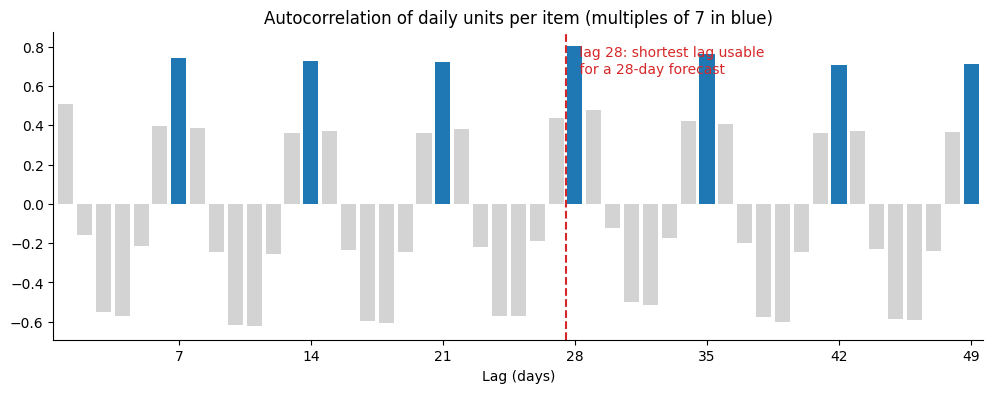

1     0.51
6     0.40
7     0.74
14    0.73
21    0.72
27    0.44
28    0.81
35    0.76
42    0.71
dtype: float64

In [31]:
# Autocorrelation: how similar is the series to itself k days earlier?
# Computed on the series divided by its centred 28-day average, so the slow trend
# does not inflate every lag. asfreq("D") keeps the calendar aligned across the
# missing Christmas days (pairs with a missing day are skipped).
series = day.set_index("date")["units_per_item"].asfreq("D")
detrended = series / series.rolling(28, center=True, min_periods=21).mean()
acf = pd.Series({lag: detrended.autocorr(lag) for lag in range(1, 50)})

colors = ["tab:blue" if lag % 7 == 0 else "lightgray" for lag in acf.index]
ax = acf.plot.bar(color=colors, width=0.8)
ax.axvline(27 - 0.5, color="tab:red", linestyle="--")
ax.text(27, acf.max(), " lag 28: shortest lag usable\n for a 28-day forecast", color="tab:red", va="top")
ax.set_title("Autocorrelation of daily units per item (multiples of 7 in blue)")
ax.set_xlabel("Lag (days)")
ax.set_xticks(range(6, 49, 7))
ax.set_xticklabels(range(7, 50, 7), rotation=0)
plt.show()

acf.loc[[1, 6, 7, 14, 21, 27, 28, 35, 42]].round(2)

### 2. Result: a strong, very regular weekly cycle

- **Saturday +25% and Sunday +29%** above the average day of the same week; **Tuesday to Thursday 16–18% below**. Monday is −5%, Friday about average. A weekend day sells **1.53×** a midweek day.
- It is not noise: the best day of the week was Saturday or Sunday in **96% of 272 complete weeks**, and the Friedman test rejects "all weekdays are equal" (χ² = 1,266, p < 10⁻²⁰⁰).
- The autocorrelation peaks at every multiple of 7 days (lag 7: 0.74, lag 28: 0.81, lag 35: 0.76). Neighbouring lags are much weaker (lag 27: 0.44).

**Modelling decisions:**
- **Weekday** as a categorical feature.
- Lag features in **multiples of 7, starting at 28** (lag_28, lag_35, lag_42): they are both allowed for a 28-day horizon and aligned with the weekly cycle. A lag such as 30 would compare a Saturday with a Monday.
- Rolling means over **whole weeks** (7, 28, 56 days), so every window contains each weekday equally often.

## 3. Events and SNAP days

**Method.** A regression on log(units per item) estimates the SNAP and event effects while controlling for the weekday and for each calendar month (year-month fixed effects absorb trend, season and mix). A coefficient *b* on the log scale is a % effect of exp(*b*) − 1. HAC (Newey-West) standard errors allow for correlation between nearby days, so the confidence intervals are not too narrow.

**A limitation to keep in mind:** in California, SNAP days are *always* the 1st to the 10th of the month. SNAP is therefore perfectly confounded with "beginning of the month" (e.g. paydays), and the data cannot fully separate the two.

In [32]:
def pct_effects(fit, keyword):
    """Coefficients whose name contains `keyword`, as % effects with 95% CI and p-value."""
    rows = [name for name in fit.params.index if keyword in name]
    ci = fit.conf_int().loc[rows]
    return pd.DataFrame({
        "effect_%": 100 * (np.exp(fit.params[rows]) - 1),
        "ci_low_%": 100 * (np.exp(ci[0]) - 1),
        "ci_high_%": 100 * (np.exp(ci[1]) - 1),
        "p_value": fit.pvalues[rows],
    }).round(4)


day["log_upi"] = np.log(day["units_per_item"])
day["year_month"] = day["date"].dt.strftime("%Y-%m")
day["event_type"] = day["event_type"].fillna("None")
day["day_of_month"] = day["date"].dt.day

snap_model = smf.ols(
    "log_upi ~ is_snap + C(event_type, Treatment('None')) + C(weekday) + C(year_month)",
    data=day,
).fit(cov_type="HAC", cov_kwds={"maxlags": 7})

print("Event days by type:", day["event_type"].value_counts().to_dict())
pd.concat([pct_effects(snap_model, "is_snap"), pct_effects(snap_model, "event_type")])

Event days by type: {'None': 1783, 'Religious': 54, 'National': 46, 'Cultural': 37, 'Sporting': 16}


,effect_%,ci_low_%,ci_high_%,p_value
is_snap[T.True],12.9163,11.6698,14.1766,0.0000
"C(event_type, Treatment('None'))[T.Cultural]",-11.1469,-13.5877,-8.6373,0.0000
"C(event_type, Treatment('None'))[T.National]",2.8037,-2.5594,8.4619,0.3118
"C(event_type, Treatment('None'))[T.Religious]",0.0117,-2.3570,2.4378,0.9924
"C(event_type, Treatment('None'))[T.Sporting]",-5.4301,-9.7162,-0.9406,0.0183


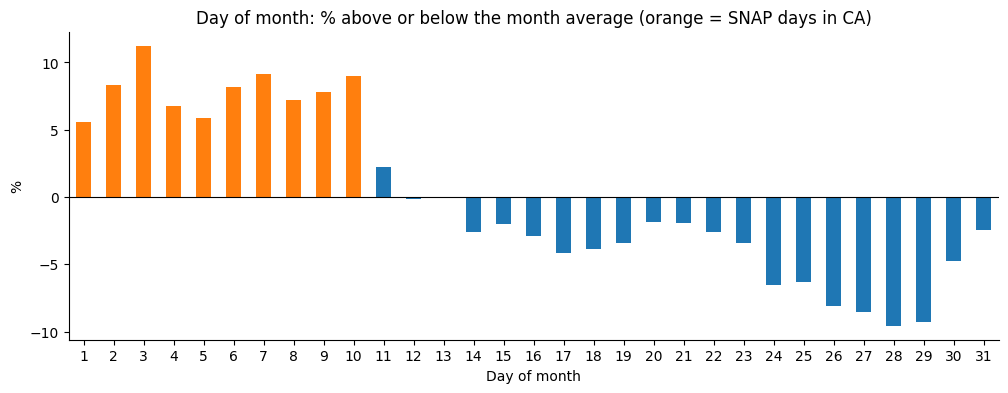

,effect_%,ci_low_%,ci_high_%,p_value
FOODS_1,1.0771,-0.4793,2.6577,0.176
FOODS_2,24.0479,22.4598,25.6566,0.000
FOODS_3,12.3307,11.2247,13.4478,0.000


In [33]:
# Day-of-month profile: each day relative to its year-month average.
day["vs_month"] = day["units_per_item"] / day.groupby("year_month")["units_per_item"].transform("mean")
dom_profile = day.groupby("day_of_month")["vs_month"].mean()

ax = (dom_profile - 1).mul(100).plot.bar(color=["tab:orange" if d <= 10 else "tab:blue" for d in dom_profile.index], rot=0)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Day of month: % above or below the month average (orange = SNAP days in CA)")
ax.set_xlabel("Day of month")
ax.set_ylabel("%")
plt.show()

# SNAP effect per department: same model, fitted separately for each department.
dept_day = q("""
    SELECT f.date, i.dept_id, AVG(f.units_sold) AS units_per_item
    FROM marts.fct_daily_sales AS f
    JOIN marts.dim_item AS i ON f.item_id = i.item_id
    WHERE NOT (month(f.date) = 12 AND day(f.date) = 25)
    GROUP BY ALL
""")
dept_day["date"] = pd.to_datetime(dept_day["date"])
dept_day = dept_day.merge(day[["date", "is_snap", "event_type", "weekday", "year_month"]], on="date")

snap_by_dept = pd.concat({
    dept: pct_effects(
        smf.ols("np.log(units_per_item) ~ is_snap + C(event_type) + C(weekday) + C(year_month)", data=g)
        .fit(cov_type="HAC", cov_kwds={"maxlags": 7}),
        "is_snap",
    )
    for dept, g in dept_day.groupby("dept_id")
}).droplevel(1)
snap_by_dept

In [34]:
# Effect of each individual event. The model is fitted on non-event days only, then
# used to predict event days: the gap between actual and predicted is the event effect.
# Each event occurs only ~5 times, so a one-sample t-test checks whether its yearly
# effects are consistently different from zero. Event names are not in the marts yet
# (dim_date only has event_type), so they are read from staging.
baseline = smf.ols("log_upi ~ is_snap + C(weekday) + C(year_month)", data=day[~day["is_event"]]).fit()
day["effect_%"] = 100 * (np.exp(day["log_upi"] - baseline.predict(day)) - 1)

event_dates = q("""
    SELECT date, event_name_1 AS event_name
    FROM staging.stg_calendar
    WHERE event_name_1 IS NOT NULL
""")
event_dates["date"] = pd.to_datetime(event_dates["date"])


def effect_on(days_before):
    """Event effect on the event day (0) or on non-event days shortly before it."""
    shifted = event_dates.assign(date=event_dates["date"] - pd.Timedelta(days=days_before))
    rows = day.merge(shifted, on="date")
    if days_before > 0:
        rows = rows[~rows["is_event"]]
    return rows.groupby("event_name")["effect_%"]


on_day = effect_on(0)
events = pd.DataFrame({
    "n_years": on_day.count(),
    "effect_on_day_%": on_day.mean(),
    "p_value": on_day.apply(lambda e: stats.ttest_1samp(e, 0).pvalue),
    "effect_1_day_before_%": effect_on(1).mean(),
    "effect_2_days_before_%": effect_on(2).mean(),
}).round(3)
events["significant_5%"] = events["p_value"] < 0.05

print(f"Events significant at 5%: {events['significant_5%'].sum()} of {len(events)}")
events.sort_values("effect_on_day_%")

Events significant at 5%: 14 of 30


,n_years,effect_on_day_%,p_value,effect_1_day_before_%,effect_2_days_before_%,significant_5%
event_name,,,,,,
NewYear,5.0,-23.702,0.010,21.727,8.085,True
Thanksgiving,5.0,-19.191,0.000,47.924,30.236,True
Mother's day,6.0,-17.994,0.001,3.629,1.246,True
Halloween,5.0,-15.114,0.008,2.788,-2.734,True
Easter,5.0,-14.973,0.015,22.289,23.008,True
Father's day,4.0,-13.902,0.003,3.169,8.866,True
NBAFinalsStart,5.0,-6.781,0.351,1.502,-6.019,False
SuperBowl,6.0,-6.354,0.160,20.539,4.261,False
Cinco De Mayo,5.0,-6.109,0.249,2.291,4.019,False


### 3. Result: SNAP days +13%; events matter by *name*, not by type

**SNAP.** Controlling for weekday and month, units per item are **12.9% higher on SNAP days** (95% CI 11.7% to 14.2%, p < 0.001).
- The day-of-month chart shows the shape: days 1–10 are 6–11% above the month average, then sales slide to about **−9% on days 26–29**.
- By department: **FOODS_2 +24%, FOODS_3 +12%, FOODS_1 +1%** (not significant, CI −0.5% to +2.7%). A pure "payday" effect would probably lift all departments; the strong differences fit a SNAP effect on eligible products. But because SNAP days in California are always days 1–10, the data **cannot fully separate SNAP from beginning-of-month effects**. The finding is stated as "beginning of month / SNAP", not as a proven SNAP effect.

**Events.** The `event_type` grouping hides most of the signal: Cultural −11%, Sporting −5%, National +3% (n.s.), Religious 0% (n.s.), because events of the same type push in opposite directions. Per individual event, **14 of 30 are significant at 5%**:
- **Lower on the day:** New Year −24%, Thanksgiving −19%, Mother's Day −18%, Halloween −15%, Easter −15%, Father's Day −14%.
- **Higher on the day:** the Monday public holidays: Labor Day +24%, Veterans Day +17%, Martin Luther King Day +14%, Memorial Day +13%, Columbus Day +12%, Presidents' Day +9%.
- **The day before** often matters more than the day itself: Thanksgiving **+48%** the day before (+30% two days before), two days before Christmas +29%, Easter +22%, Independence Day +23%, New Year's Eve +22%, Super Bowl +21%, Valentine's Day +15%.
- Caution: each event occurs only 4–6 times, and with 30 tests about 1–2 "significant" results are expected by chance. The large, consistent effects above are the ones to trust.

**Modelling decisions:**
- **`is_snap`** and **day of month** as features (the end-of-month dip is a separate effect from SNAP); `dept_id` as a feature lets the model learn that SNAP matters for FOODS_2 and FOODS_3 but not FOODS_1.
- Use the **event name**, not the event type → add `event_name` to `dim_date` in dbt.
- Add **"days until the next event"** (or flags for 1 and 2 days before the major events). Events are known in advance, so these features do not leak.

## 4. Price: do sales rise when the price drops?

**Method.** Prices are weekly, so this section works at item-week level (complete weeks only). Three angles:
1. **How often do prices change**, and are drops temporary (promotions) or permanent?
2. **Price elasticity**: a regression of log(weekly units + 1) on log(price relative to the item's median price), with item and week fixed effects. The item effects remove "expensive items sell less"; the week effects remove season and trend. So the elasticity comes only from *the same item* selling more or less when *its own* price changes. Standard errors are clustered by item.
3. **Before/after**: units in the week of a price change vs. the item's previous 4 weeks, compared with weeks without a change.

In [35]:
weekly = q("""
    SELECT
        f.item_id,
        i.dept_id,
        d.wm_yr_wk,
        SUM(f.units_sold)        AS units,
        COUNT(*)                 AS n_days,
        ANY_VALUE(f.sell_price)  AS price
    FROM marts.fct_daily_sales AS f
    JOIN marts.dim_date AS d ON f.date = d.date
    JOIN marts.dim_item AS i ON f.item_id = i.item_id
    WHERE NOT (month(f.date) = 12 AND day(f.date) = 25)
    GROUP BY ALL
""")
weekly = weekly[weekly["n_days"] == 7].sort_values(["item_id", "wm_yr_wk"]).reset_index(drop=True)

by_item = weekly.groupby("item_id")
weekly["prev_price"] = by_item["price"].shift(1)
weekly["price_4w_later"] = by_item["price"].shift(-4)
weekly["changed"] = weekly["prev_price"].notna() & (weekly["price"] != weekly["prev_price"])
weekly["change_%"] = 100 * (weekly["price"] / weekly["prev_price"] - 1)

changes = weekly[weekly["changed"]]
drops = changes[changes["change_%"] < 0]
n_changes_per_item = by_item["changed"].sum()

print(f"Item-weeks: {len(weekly):,}, with a price change: {weekly['changed'].mean():.1%}")
print(f"Items whose price never changed: {(n_changes_per_item == 0).sum()} of {len(n_changes_per_item)}")
print(f"Price changes per item: median {n_changes_per_item.median():.0f}, 90th percentile {n_changes_per_item.quantile(0.9):.0f}")
print(f"Share of changes that are decreases: {(changes['change_%'] < 0).mean():.0%}")
print(f"Size of changes: median |change| {changes['change_%'].abs().median():.1f}%")
print(f"Drops back at (or above) the old price 4 weeks later: "
      f"{(drops['price_4w_later'] >= drops['prev_price']).sum()} of {len(drops)}")

Item-weeks: 316,516, with a price change: 1.3%
Items whose price never changed: 312 of 1437
Price changes per item: median 2, 90th percentile 7
Share of changes that are decreases: 38%
Size of changes: median |change| 7.6%
Drops back at (or above) the old price 4 weeks later: 195 of 1540


In [36]:
def demean_two_way(df, cols, a="item_id", b="wm_yr_wk", n_iter=20):
    """Remove item and week means by alternating projections (exact two-way fixed effects)."""
    out = df[cols].copy()
    for _ in range(n_iter):
        out -= out.groupby(df[a]).transform("mean")
        out -= out.groupby(df[b]).transform("mean")
    return out


weekly["log_units"] = np.log1p(weekly["units"])
weekly["log_rel_price"] = np.log(weekly["price"] / by_item["price"].transform("median"))
weekly[["y", "x"]] = demean_two_way(weekly, ["log_units", "log_rel_price"]).to_numpy()


def elasticity(df):
    fit = smf.ols("y ~ x - 1", data=df).fit(cov_type="cluster", cov_kwds={"groups": df["item_id"]})
    lo, hi = fit.conf_int().loc["x"]
    return pd.Series({"elasticity": fit.params["x"], "ci_low": lo, "ci_high": hi, "p_value": fit.pvalues["x"]})


elasticities = pd.concat(
    {"all FOODS": elasticity(weekly), **{d: elasticity(g) for d, g in weekly.groupby("dept_id")}}, axis=1
).T.round(3)
elasticities

,elasticity,ci_low,ci_high,p_value
all FOODS,-2.306,-2.666,-1.946,0.0
FOODS_1,-1.911,-2.656,-1.166,0.0
FOODS_2,-2.006,-2.574,-1.439,0.0
FOODS_3,-2.531,-3.051,-2.011,0.0


In [37]:
# Before/after: units in the week of a price change vs. the item's average of the
# previous 4 weeks. Weeks without a change show the "normal" week-to-week drift.
weekly["prev_4w_units"] = by_item["units"].transform(lambda s: s.shift(1).rolling(4).mean())
has_base = weekly["prev_4w_units"] > 0
weekly["vs_prev_4w_%"] = 100 * (weekly["units"] / weekly["prev_4w_units"] - 1)

groups = {
    "no price change": weekly[has_base & ~weekly["changed"]],
    "price drop 0-5%": weekly[has_base & weekly["change_%"].between(-5, 0, inclusive="left")],
    "price drop 5-10%": weekly[has_base & weekly["change_%"].between(-10, -5, inclusive="left")],
    "price drop >10%": weekly[has_base & (weekly["change_%"] < -10)],
    "price increase": weekly[has_base & (weekly["change_%"] > 0)],
}
before_after = pd.DataFrame({
    "n_weeks": {k: len(g) for k, g in groups.items()},
    "median_vs_prev_4w_%": {k: g["vs_prev_4w_%"].median() for k, g in groups.items()},
})
# Mann-Whitney U test: are weeks with a price drop different from weeks without a change?
no_change = groups["no price change"]["vs_prev_4w_%"]
before_after["p_vs_no_change"] = {
    k: (np.nan if k == "no price change" else stats.mannwhitneyu(g["vs_prev_4w_%"], no_change).pvalue)
    for k, g in groups.items()
}
before_after.round(4)

,n_weeks,median_vs_prev_4w_%,p_vs_no_change
no price change,271056,-4.7619,NaN
price drop 0-5%,273,0.0000,0.0118
price drop 5-10%,324,18.1985,0.0000
price drop >10%,441,15.0000,0.0000
price increase,2155,-11.1111,0.1724


### 4. Result: sales respond to price, but prices rarely change

- **Price changes are rare:** only **1.3% of item-weeks** have a change, **312 items (22%) never changed price** in five years, and the median item changed price twice.
- **Most changes are permanent, not promotions:** only **195 of 1,540 price drops (13%)** were back at the old price four weeks later.
- **Within the same item, lower prices sell more:** price elasticity ≈ **−2.3** (95% CI −2.7 to −1.9): a 10% lower price goes with roughly 25% more units (0.9^−2.3 ≈ 1.27). Similar in all departments (−1.9 to −2.5).
- **Before/after:** in weeks with a price drop of 5–10% or more than 10%, units were a median **+18% / +15%** above the previous four weeks, against −5% in weeks without a change (Mann-Whitney p < 0.001). Small drops (< 5%) had only a small effect (median 0%, p = 0.01). Price **increases** (median −11%) were *not* significantly different from normal weeks (p = 0.17).
- **Caution:** this is observational data. Prices are not changed at random (a price cut may come with a display or advert; a cut may also be a clearance of a weak item), so −2.3 is an association, not a proven causal elasticity.

**Modelling decisions:**
- Price features: **`sell_price`**, **price relative to the item's recent average price**, and **price change vs last week**. Future prices are known in advance, so they are allowed for the forecast window.
- The reference price must use **past weeks only**. The median over the whole history used above is fine for analysis, but as a feature it would leak future prices.
- Because prices change rarely, expect price to matter in a few weeks for some items, not to be a top feature overall.

## 5. Intermittency: fast, medium and slow movers

**Method.** Two complementary classifications per item (after launch, 25 December excluded):
- **Velocity** by average units per day: slow (< 1), medium (1–5), fast (≥ 5). Simple to explain to a store manager.
- **Syntetos-Boylan demand pattern**, the standard classification in demand forecasting. It uses **ADI** (average days between two sales) and **CV²** (variability of the sale sizes when there is a sale), with the published cut-offs 1.32 and 0.49: *smooth* (frequent, stable), *erratic* (frequent, variable sizes), *intermittent* (rare, stable sizes), *lumpy* (rare and variable).

In [38]:
items = q("""
    SELECT
        f.item_id,
        i.dept_id,
        AVG(f.units_sold)                                     AS mean_units,
        AVG((f.units_sold = 0)::INT)                          AS zero_share,
        SUM(f.units_sold)                                     AS total_units,
        COUNT(*) / COUNT(*) FILTER (WHERE f.units_sold > 0)   AS adi,
        POWER(STDDEV_SAMP(f.units_sold) FILTER (WHERE f.units_sold > 0)
              / AVG(f.units_sold) FILTER (WHERE f.units_sold > 0), 2) AS cv2
    FROM marts.fct_daily_sales AS f
    JOIN marts.dim_item AS i ON f.item_id = i.item_id
    WHERE NOT (month(f.date) = 12 AND day(f.date) = 25)
    GROUP BY ALL
""")
items["velocity"] = pd.cut(items["mean_units"], [0, 1, 5, np.inf], right=False,
                           labels=["slow (<1/day)", "medium (1-5/day)", "fast (>=5/day)"])
items["pattern"] = np.select(
    [(items["adi"] < 1.32) & (items["cv2"] < 0.49), items["adi"] < 1.32, items["cv2"] < 0.49],
    ["smooth", "erratic", "intermittent"],
    default="lumpy",
)


def share_table(col):
    t = items.groupby(col, observed=True).agg(
        n_items=("item_id", "count"),
        median_zero_share=("zero_share", "median"),
        median_units_per_day=("mean_units", "median"),
        units=("total_units", "sum"),
    )
    t["item_share"] = t["n_items"] / t["n_items"].sum()
    t["volume_share"] = t["units"] / t["units"].sum()
    return t.drop(columns="units").round(3)


ranked = items.sort_values("total_units", ascending=False)
cum_volume = ranked["total_units"].cumsum() / ranked["total_units"].sum()
print(f"Items with zero sales on more than half of their days: {(items['zero_share'] > 0.5).mean():.0%}")
print(f"Median share of zero days per item: {items['zero_share'].median():.0%}")
print(f"Items needed for 50% / 80% of all units: {(cum_volume < 0.5).sum() + 1} / {(cum_volume < 0.8).sum() + 1} "
      f"of {len(items)}")
display(share_table("velocity"))
share_table("pattern")

Items with zero sales on more than half of their days: 49%
Median share of zero days per item: 49%
Items needed for 50% / 80% of all units: 141 / 510 of 1437


,n_items,median_zero_share,median_units_per_day,item_share,volume_share
velocity,,,,,
slow (<1/day),649,0.656,0.607,0.452,0.106
medium (1-5/day),653,0.373,1.743,0.454,0.410
fast (>=5/day),135,0.142,7.938,0.094,0.484


,n_items,median_zero_share,median_units_per_day,item_share,volume_share
pattern,,,,,
erratic,57,0.167,5.247,0.040,0.120
intermittent,836,0.561,0.801,0.582,0.274
lumpy,390,0.479,1.338,0.271,0.227
smooth,154,0.135,4.490,0.107,0.379


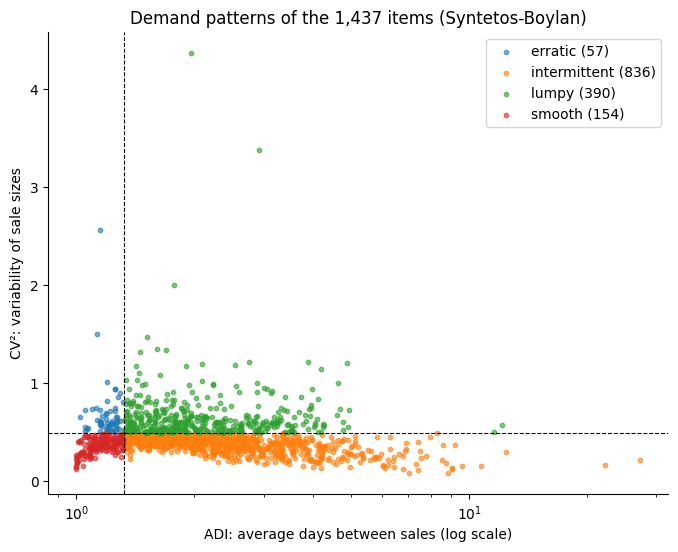

In [39]:
fig, ax = plt.subplots(figsize=(8, 6))
for pattern, g in items.groupby("pattern"):
    ax.scatter(g["adi"], g["cv2"], s=10, alpha=0.6, label=f"{pattern} ({len(g)})")
ax.axvline(1.32, color="black", linewidth=0.8, linestyle="--")
ax.axhline(0.49, color="black", linewidth=0.8, linestyle="--")
ax.set_xscale("log")
ax.set_xlabel("ADI: average days between sales (log scale)")
ax.set_ylabel("CV²: variability of sale sizes")
ax.set_title("Demand patterns of the 1,437 items (Syntetos-Boylan)")
ax.legend()
plt.show()

### 5. Result: most items are intermittent; a few fast movers carry the volume

- The **median item sells nothing on 49% of its days**, and 49% of items have zero sales on more than half of their days.
- **Volume is concentrated:** fast movers (≥ 5 units/day) are **9% of items but 48% of units**; slow movers (< 1/day) are **45% of items but 11% of units**. **141 items (10%) make up half of all units**; 510 (35%) make up 80%.
- **Syntetos-Boylan:** 58% intermittent, 27% lumpy, 11% smooth, 4% erratic. So **85% of items have intermittent or lumpy demand**, where methods built for smooth series (and plain MSE) struggle.
- Note: zero shares are inflated by the long out-of-stock-like zero runs found in section 6.

**Modelling decisions:**
- LightGBM with a **Tweedie** (or Poisson) objective: built for non-negative counts with many zeros, unlike a squared-error objective.
- Use **RMSSE** (scale-free) so slow items count as much as fast ones, and report errors **by velocity group and demand pattern**, plus **bias** per group (intermittent items are prone to systematic over-forecasting).
- Because 10% of items carry half the volume, also report a **volume-weighted** error: a store manager cares most about the items that sell.

## 6. Data issues

**Method.** Three checks:
1. **Long runs of zero sales in the middle of an item's history.** A run of *L* zero days is compared with the item's own share of zero days *p*: if days were independent, a run that long would have probability about *p^L*. Runs of at least 28 days with *p^L* < 10⁻⁶ are flagged as **unlikely to be real zero demand** (more likely out of stock, not on the shelf, or delisted). With about 2,000 days per item, the chance of a false flag per item is around 0.2%.
2. **Items whose sales stopped** before the end of the data.
3. **Extreme spikes**: days with at least 10× the item's typical (median non-zero) sales and at least 20 units.

In [40]:
# Every run of consecutive zero-sales days per item (a new group starts after each sale).
zero_runs = q("""
    WITH numbered AS (
        SELECT
            item_id, date, units_sold,
            SUM((units_sold > 0)::INT) OVER (PARTITION BY item_id ORDER BY date) AS run_id
        FROM marts.fct_daily_sales
    )
    SELECT item_id, run_id, MIN(date) AS start_date, MAX(date) AS end_date, COUNT(*) AS run_days
    FROM numbered
    WHERE units_sold = 0
    GROUP BY item_id, run_id
""")
last_date = q("SELECT MAX(date) AS d FROM marts.fct_daily_sales")["d"][0]

zero_runs = zero_runs.merge(items[["item_id", "mean_units", "zero_share"]], on="item_id")
zero_runs["prob_if_random"] = zero_runs["zero_share"] ** zero_runs["run_days"]
zero_runs["to_end"] = zero_runs["end_date"] == last_date
zero_runs["unlikely"] = (zero_runs["run_days"] >= 28) & (zero_runs["prob_if_random"] < 1e-6)

flagged = zero_runs[zero_runs["unlikely"] & ~zero_runs["to_end"]]
n_rows = q("SELECT COUNT(*) AS n FROM marts.fct_daily_sales")["n"][0]
print(f"Unlikely zero runs in mid-history: {len(flagged):,} runs in {flagged['item_id'].nunique()} items "
      f"({flagged['item_id'].nunique() / len(items):.0%} of items)")
print(f"Days inside these runs: {flagged['run_days'].sum():,} = {flagged['run_days'].sum() / n_rows:.1%} of the fact table")
print(f"Run length: median {flagged['run_days'].median():.0f} days, longest {flagged['run_days'].max()} days")
flagged.sort_values("mean_units", ascending=False).head(8)[
    ["item_id", "start_date", "end_date", "run_days", "mean_units", "zero_share"]
].round(2)

Unlikely zero runs in mid-history: 3,288 runs in 1135 items (79% of items)
Days inside these runs: 345,002 = 15.3% of the fact table
Run length: median 83 days, longest 1099 days


,item_id,start_date,end_date,run_days,mean_units,zero_share
93143,FOODS_3_090,2014-02-08,2014-03-08,29,66.56,0.24
303009,FOODS_3_090,2014-05-13,2014-06-10,29,66.56,0.24
150471,FOODS_3_090,2015-12-04,2016-01-06,34,66.56,0.24
150470,FOODS_3_090,2014-12-01,2015-01-03,34,66.56,0.24
245860,FOODS_3_090,2015-02-12,2015-03-11,28,66.56,0.24
245858,FOODS_3_090,2011-02-08,2011-09-22,227,66.56,0.24
264893,FOODS_3_090,2015-05-14,2015-06-13,31,66.56,0.24
257819,FOODS_3_120,2012-10-13,2013-02-05,116,40.12,0.19


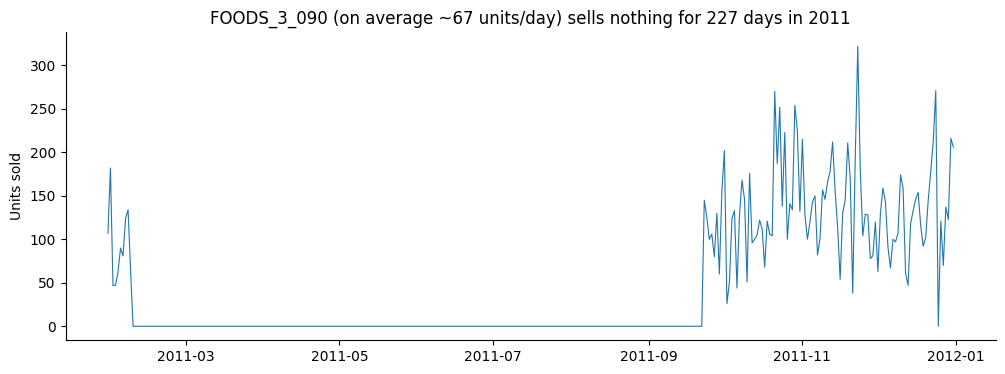

In [41]:
# Example: the store's best-selling FOODS item, first year.
example = q("""
    SELECT date, units_sold FROM marts.fct_daily_sales
    WHERE item_id = 'FOODS_3_090' AND date < DATE '2012-01-01'
    ORDER BY date
""")
fig, ax = plt.subplots()
ax.plot(example["date"], example["units_sold"], color="tab:blue", linewidth=0.8)
ax.set_title("FOODS_3_090 (on average ~67 units/day) sells nothing for 227 days in 2011")
ax.set_ylabel("Units sold")
plt.show()

In [42]:
# 2. Items with no sales at the end of the data (possibly delisted).
stopped = zero_runs[zero_runs["to_end"] & (zero_runs["run_days"] >= 28)]
print(f"Items with no sales in their last 28+ days: {len(stopped)} "
      f"(median {stopped['run_days'].median():.0f} days, longest {stopped['run_days'].max()})")

# Launch check from Stage 1: items with 28+ zero days right after their launch date.
late_starters = q("""
    SELECT item_id, launch_date, first_sale_date, first_sale_date - launch_date AS days_to_first_sale
    FROM marts.dim_item
    WHERE first_sale_date - launch_date >= 28
""")
display(late_starters)

# 3. Extreme spikes.
spikes = q("""
    WITH typical AS (
        SELECT item_id, MEDIAN(units_sold) FILTER (WHERE units_sold > 0) AS median_nonzero
        FROM marts.fct_daily_sales
        GROUP BY item_id
    )
    SELECT f.item_id, f.date, f.units_sold, t.median_nonzero,
           f.units_sold / t.median_nonzero AS times_typical
    FROM marts.fct_daily_sales AS f
    JOIN typical AS t ON f.item_id = t.item_id
    WHERE f.units_sold >= 10 * t.median_nonzero AND f.units_sold >= 20
    ORDER BY times_typical DESC
""")
print(f"Spike days: {len(spikes)} in {spikes['item_id'].nunique()} items "
      f"({len(spikes) / n_rows:.3%} of rows)")
spikes.head(8)

Items with no sales in their last 28+ days: 25 (median 52 days, longest 361)


,item_id,launch_date,first_sale_date,days_to_first_sale
0,FOODS_1_051,2013-05-25,2014-03-06,285


Spike days: 315 in 125 items (0.014% of rows)


,item_id,date,units_sold,median_nonzero,times_typical
0,FOODS_3_785,2012-06-22,648,12.0,54.0
1,FOODS_2_255,2011-11-22,94,2.0,47.0
2,FOODS_3_326,2012-10-04,81,2.0,40.5
3,FOODS_3_578,2012-05-12,80,2.0,40.0
4,FOODS_3_069,2013-12-31,78,2.0,39.0
5,FOODS_1_088,2016-05-18,77,2.0,38.5
6,FOODS_2_255,2011-11-19,75,2.0,37.5
7,FOODS_3_069,2012-12-31,73,2.0,36.5


### 6. Result: 15% of the data looks like out-of-stock, not zero demand

1. **Long, improbable zero runs.** **3,288 runs** of 28+ zero days, each with probability below 10⁻⁶ given the item's own zero rate, in **1,135 items (79%)**. They cover **345,002 rows = 15.3% of the fact table** (median 83 days, longest 1,099). The clearest example: the store's best-selling FOODS item, FOODS_3_090 (about 67 units/day), sold **nothing for 227 days in 2011**, plus several month-long gaps later. That pattern is not plausible as zero demand. More likely the product was **out of stock, not on the shelf, or temporarily delisted**. The dataset has no stock levels, so this cannot be confirmed, but in a warehouse or store system a stockout is recorded as zero sales, not as missing demand.
2. **25 items** had no sales in their last 28+ days (median 52, longest 361): possibly delisted.
3. **Launch rule check (Stage 1):** only **1 of 1,437 items** (FOODS_1_051) took 28+ days from first price to first sale (285 days). The "launch = first price" rule holds for the rest.
4. **Spikes:** 315 days in 125 items (0.014% of rows) with at least 10× the item's typical sales; the largest is 648 units for FOODS_3_785 (typically 12). Probably genuine bulk purchases: kept, but they inflate RMSE.

**Modelling decisions:**
- Flag days inside improbable zero runs as **`likely_out_of_stock`** and **exclude them from training labels**: otherwise the model learns that best sellers sometimes have zero demand for months. Report evaluation **with and without** flagged days.
- The flag uses the whole history (it knows how long a run lasts), so it may only be used to **clean training data**, never as a feature at forecast time. A legitimate feature is **days since last sale**, measured at the forecast origin.
- Keep spikes, and report **MAE next to RMSE**, since RMSE is dominated by a few extreme days.